# EPL Snapshot Analysis

Loads `data/processed/epl_snapshots.csv` into a DataFrame. Each row is one fixture at one forecast horizon (8 per match). See `reports/epl_dataset_guide.md` for column definitions.

In [17]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", None)

# Works whether the notebook runs from notebooks/ or the repo root
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

df = pd.read_csv(ROOT / "data" / "processed" / "epl_snapshots.csv")

# Order horizons chronologically instead of alphabetically
HORIZON_ORDER = ["pregame_30m", "pregame_closing_5m", "ingame_15m", "ingame_30m",
                 "ingame_45m", "ingame_60m", "ingame_75m", "ingame_90m"]
df["forecast_horizon"] = pd.Categorical(df["forecast_horizon"], categories=HORIZON_ORDER, ordered=True)

print(f"{len(df):,} rows, {df['fixture_id'].nunique():,} fixtures, {df.shape[1]} columns")

3,920 rows, 490 fixtures, 44 columns


In [18]:
df.head()

,fixture_id,event_id,league,home_team,away_team,market_id,condition_id,draw_token_id,scheduled_kickoff_utc,actual_kickoff_utc,forecast_horizon,horizon_type,requested_match_minute,requested_horizon_minutes,requested_timestamp_utc,selected_observation_timestamp_utc,forecast_probability,observation_age_minutes,max_lookback_minutes,final_score_home,final_score_away,final_draw_label,api_settled_draw,analysis_eligible,eligibility_reason,fixture_result_eligible,price_observation_status,timing_status,timing_precision,clock_bracket_seconds,wallclock_bracket_seconds,left_play_timestamp_utc,right_play_timestamp_utc,in_progress_check,token_mapping_status,settlement_crosscheck_status,scheduled_kickoff_source,draw_label_source,market_raw_ref,token_metadata_raw_ref,price_history_raw_ref,result_source_raw_ref,result_summary_raw_ref,collection_errors
0,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,pregame_30m,pregame,NaN,30.0,2025-08-15T18:30:00+00:00,2025-08-15T18:29:02+00:00,0.145,0.966667,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,scheduled_kickoff_relative,scheduled_kickoff,NaN,NaN,NaN,NaN,NaN,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
1,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,pregame_closing_5m,pregame,NaN,5.0,2025-08-15T18:55:00+00:00,2025-08-15T18:54:03+00:00,0.145,0.950000,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,scheduled_kickoff_relative,scheduled_kickoff,NaN,NaN,NaN,NaN,NaN,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
2,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,ingame_15m,in_game_match_clock,15.0,NaN,2025-08-15T19:16:04+00:00,2025-08-15T19:16:02+00:00,0.170,0.033333,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,match_clock_aligned,interpolated_between_commentary_plays,148.0,148.0,2025-08-15T19:15:00+00:00,2025-08-15T19:17:28+00:00,passed,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
3,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,ingame_30m,in_game_match_clock,30.0,NaN,2025-08-15T19:31:04+00:00,2025-08-15T19:31:03+00:00,0.200,0.016667,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,match_clock_aligned,interpolated_between_commentary_plays,213.0,213.0,2025-08-15T19:28:23+00:00,2025-08-15T19:31:56+00:00,passed,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
4,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool F

## Coverage by horizon

In [19]:
summary = df.groupby("forecast_horizon", observed=True).agg(
    rows=("fixture_id", "size"),
    eligible=("analysis_eligible", "sum"),
    has_price=("forecast_probability", lambda s: s.notna().sum()),
)
summary

,rows,eligible,has_price
forecast_horizon,,,
pregame_30m,490,486,487
pregame_closing_5m,490,486,487
ingame_15m,490,407,407
ingame_30m,490,422,422
ingame_45m,490,392,392
ingame_60m,490,451,451
ingame_75m,490,467,467
ingame_90m,490,443,443


## Analysis DataFrame

Eligible rows only. For calibration, pick **one** `forecast_horizon` at a time; don't pool the eight rows per match as independent observations.

In [20]:
eligible = df[df["analysis_eligible"]].copy()
print(f"{len(eligible):,} eligible rows across {eligible['fixture_id'].nunique():,} fixtures")
eligible.head()

3,554 eligible rows across 486 fixtures


,fixture_id,event_id,league,home_team,away_team,market_id,condition_id,draw_token_id,scheduled_kickoff_utc,actual_kickoff_utc,forecast_horizon,horizon_type,requested_match_minute,requested_horizon_minutes,requested_timestamp_utc,selected_observation_timestamp_utc,forecast_probability,observation_age_minutes,max_lookback_minutes,final_score_home,final_score_away,final_draw_label,api_settled_draw,analysis_eligible,eligibility_reason,fixture_result_eligible,price_observation_status,timing_status,timing_precision,clock_bracket_seconds,wallclock_bracket_seconds,left_play_timestamp_utc,right_play_timestamp_utc,in_progress_check,token_mapping_status,settlement_crosscheck_status,scheduled_kickoff_source,draw_label_source,market_raw_ref,token_metadata_raw_ref,price_history_raw_ref,result_source_raw_ref,result_summary_raw_ref,collection_errors
0,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,pregame_30m,pregame,NaN,30.0,2025-08-15T18:30:00+00:00,2025-08-15T18:29:02+00:00,0.145,0.966667,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,scheduled_kickoff_relative,scheduled_kickoff,NaN,NaN,NaN,NaN,NaN,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
1,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,pregame_closing_5m,pregame,NaN,5.0,2025-08-15T18:55:00+00:00,2025-08-15T18:54:03+00:00,0.145,0.950000,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,scheduled_kickoff_relative,scheduled_kickoff,NaN,NaN,NaN,NaN,NaN,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
2,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,ingame_15m,in_game_match_clock,15.0,NaN,2025-08-15T19:16:04+00:00,2025-08-15T19:16:02+00:00,0.170,0.033333,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,match_clock_aligned,interpolated_between_commentary_plays,148.0,148.0,2025-08-15T19:15:00+00:00,2025-08-15T19:17:28+00:00,passed,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
3,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool FC,AFC Bournemouth,571014,0x37fcf828abb63fd986423db5829bd2d79b4c1b6c2380...,1642073973589755423467059330474052577329642333...,2025-08-15T19:00:00+00:00,NaN,ingame_30m,in_game_match_clock,30.0,NaN,2025-08-15T19:31:04+00:00,2025-08-15T19:31:03+00:00,0.200,0.016667,5,4.0,2.0,0.0,0.0,True,NaN,True,selected,match_clock_aligned,interpolated_between_commentary_plays,213.0,213.0,2025-08-15T19:28:23+00:00,2025-08-15T19:31:56+00:00,passed,matched,matched,ESPN scoreboard event date,ESPN completed score feed,data/raw/gamma_events/8aa7ab863cc8b624e1ab.json,data/raw/clob_market_details/885d2f2d588069f60...,data/raw/clob_prices_history/2b612172d457ed532...,data/raw/espn_scoreboard/6768c1ab5294c43c1f47....,data/raw/espn_match_summary/670188303076d73619...,[]
4,fx-9f852b235c71d6f9e520,35478,Premier League,Liverpool F

## Binning and calibration toolkit

Reusable functions for any set of bin edges. Each analysis section below just defines its edges and calls these.

- Bins are `[lower, upper)`: the lower edge is inclusive, so a price of exactly 0.10 goes in the bin that starts at 10%. A price of exactly 1.0 goes in the last bin.
- Each fixture appears at most once per horizon, so within one horizon the observations are independent matches.
- Calibration points are plotted at the bin's **mean** quoted probability. Error bars are 95% Wilson intervals; hollow markers flag bins with fewer than `SMALL_BIN` matches and are left off the connecting line.

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# --- Chart styling: one hue, recessive grid/axes, text in neutral ink ---
SERIES = "#2a78d6"      # observations
REFERENCE = "#8a8984"   # perfect-calibration line
TEXT_SECONDARY = "#52514e"
GRID = "#e4e3df"
SMALL_BIN = 20          # bins with fewer matches are drawn hollow and not connected

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "font.size": 9,
})

HORIZON_TITLES = {
    "pregame_30m": "30 min pre-kickoff", "pregame_closing_5m": "5 min pre-kickoff",
    "ingame_15m": "Minute 15", "ingame_30m": "Minute 30", "ingame_45m": "Minute 45",
    "ingame_60m": "Minute 60", "ingame_75m": "Minute 75", "ingame_90m": "Minute 90",
}


def pct(x):
    """0.15 -> '15', 0.125 -> '12.5'"""
    return f"{x * 100:g}"


def make_bin_labels(edges):
    return [f"{pct(lo)}–{pct(hi)}%" for lo, hi in zip(edges[:-1], edges[1:])]


def assign_bins(data, edges, prob_col="forecast_probability"):
    """Return a copy of `data` with a categorical `prob_bin` column for the given edges."""
    edges = np.asarray(edges, dtype=float)
    assert edges[0] == 0 and edges[-1] == 1 and np.all(np.diff(edges) > 0), "edges must rise from 0 to 1"
    out = data.copy()
    out["prob_bin"] = pd.cut(
        out[prob_col].clip(upper=np.nextafter(1.0, 0)),  # put exactly 1.0 in the last bin
        bins=edges, labels=make_bin_labels(edges), right=False, include_lowest=True,
    )
    assert out["prob_bin"].notna().all(), "some probabilities fell outside the bins"
    return out


def bin_count_table(binned):
    """Matches per horizon (rows) x bin (columns), including empty bins."""
    return binned.groupby(["forecast_horizon", "prob_bin"], observed=False).size().unstack("prob_bin")


def wilson_interval(successes, n, z=1.96):
    """95% Wilson score interval for a binomial proportion."""
    successes = np.asarray(successes, dtype=float)
    n = np.asarray(n, dtype=float)
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def calibration_table(binned):
    """Per horizon and non-empty bin: matches, draws, mean market prob, actual draw rate, 95% CI, gap."""
    cal = (
        binned.groupby(["forecast_horizon", "prob_bin"], observed=True)
        .agg(
            matches=("fixture_id", "nunique"),
            draws=("final_draw_label", "sum"),
            mean_market_prob=("forecast_probability", "mean"),
        )
        .reset_index()
    )
    cal["draws"] = cal["draws"].astype(int)
    cal["actual_draw_rate"] = cal["draws"] / cal["matches"]
    cal["ci_low"], cal["ci_high"] = wilson_interval(cal["draws"], cal["matches"])
    cal["gap"] = cal["actual_draw_rate"] - cal["mean_market_prob"]
    return cal


def brier_score(group):
    return ((group["forecast_probability"] - group["final_draw_label"]) ** 2).mean()


def horizon_summary_table(binned, cal):
    """Per horizon: matches, draw rate, mean market prob, Brier score and ECE for these bins."""
    rows = {}
    for horizon, group in binned.groupby("forecast_horizon", observed=True):
        c = cal[cal["forecast_horizon"] == horizon]
        rows[horizon] = {
            "matches": group["fixture_id"].nunique(),
            "draw_rate": group["final_draw_label"].mean(),
            "mean_market_prob": group["forecast_probability"].mean(),
            "brier": brier_score(group),
            "ece": np.average(c["gap"].abs(), weights=c["matches"]),
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("forecast_horizon")


def style_axis(ax, edges):
    """Recessive grid with a vertical gridline at every bin edge; x labels every 20 points."""
    ax.grid(True, axis="y", color=GRID, linewidth=0.8)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_xticklabels([pct(t) for t in np.linspace(0, 1, 6)])
    ax.set_xticks(edges, minor=True)
    ax.grid(True, which="minor", axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(which="both", length=0)


def plot_bin_counts(binned, edges, title):
    """Small multiples: matches per bin for each horizon. Bars span their true bin width."""
    edges = np.asarray(edges, dtype=float)
    counts = bin_count_table(binned)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
    for ax, horizon in zip(axes.flat, HORIZON_ORDER):
        values = counts.loc[horizon].to_numpy()
        # Slightly narrower than the bin so adjacent bars keep a small gap
        ax.bar(edges[:-1] + 0.004, values, width=np.diff(edges) - 0.008, align="edge",
               color=SERIES, edgecolor="white", linewidth=0.5)
        ax.set_title(f"{HORIZON_TITLES[horizon]}  (n = {int(values.sum())})", loc="left")
        style_axis(ax, edges)
        ax.set_xlim(0, 1)
    for ax in axes[1]:
        ax.set_xlabel("Market draw probability (%); gridlines mark bin edges")
    for ax in axes[:, 0]:
        ax.set_ylabel("Matches")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    plt.show()


def plot_calibration(binned, cal, edges, title):
    """Small multiples: actual draw rate vs mean market probability per bin, against y = x."""
    edges = np.asarray(edges, dtype=float)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.5), sharex=True, sharey=True)
    for ax, horizon in zip(axes.flat, HORIZON_ORDER):
        c = cal[cal["forecast_horizon"] == horizon]
        big = c["matches"] >= SMALL_BIN

        ax.plot([0, 1], [0, 1], linestyle="--", color=REFERENCE, linewidth=1.2, label="Perfect calibration")
        yerr = np.vstack([c["actual_draw_rate"] - c["ci_low"], c["ci_high"] - c["actual_draw_rate"]])
        ax.errorbar(c["mean_market_prob"], c["actual_draw_rate"], yerr=yerr,
                    fmt="none", ecolor=SERIES, elinewidth=1, alpha=0.45, capsize=0)
        ax.plot(c.loc[big, "mean_market_prob"], c.loc[big, "actual_draw_rate"],
                color=SERIES, linewidth=1.5, zorder=3)
        ax.scatter(c.loc[big, "mean_market_prob"], c.loc[big, "actual_draw_rate"], s=40, color=SERIES,
                   edgecolor="white", linewidth=1.5, zorder=4, label=f"Bin with ≥{SMALL_BIN} matches")
        ax.scatter(c.loc[~big, "mean_market_prob"], c.loc[~big, "actual_draw_rate"], s=40, facecolor="white",
                   edgecolor=SERIES, linewidth=1.5, zorder=4, label=f"Bin with <{SMALL_BIN} matches")
        for _, row in c.iterrows():
            ax.annotate(f"{row['matches']}", (row["mean_market_prob"], row["actual_draw_rate"]),
                        textcoords="offset points", xytext=(-6, 5), ha="right", fontsize=7, color=TEXT_SECONDARY)

        group = binned[binned["forecast_horizon"] == horizon]
        ax.set_title(f"{HORIZON_TITLES[horizon]}  (n = {c['matches'].sum()}, Brier {brier_score(group):.3f})",
                     loc="left")
        style_axis(ax, edges)
        ax.grid(True, axis="y", color=GRID, linewidth=0.8)
        ax.set_yticks(np.linspace(0, 1, 6))
        ax.set_yticklabels([pct(t) for t in np.linspace(0, 1, 6)])
        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-0.02, 1.04)
        ax.set_aspect("equal")
    for ax in axes[1]:
        ax.set_xlabel("Market draw probability (%, mean within bin)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Matches ending in a draw (%)")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False, bbox_to_anchor=(0.99, 0.985))
    fig.suptitle(title, x=0.01, y=0.985, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()


def run_calibration_analysis(data, edges, name):
    """Bin, plot counts and calibration, and return the tables for one set of bin edges."""
    binned = assign_bins(data, edges)
    cal = calibration_table(binned)
    plot_bin_counts(binned, edges, f"Distribution of quoted draw probabilities by horizon: {name}")
    plot_calibration(binned, cal, edges, f"Calibration of Polymarket draw prices by horizon: {name}")
    return {
        "binned": binned,
        "counts": bin_count_table(binned),
        "calibration": cal,
        "summary": horizon_summary_table(binned, cal),
    }

## Analysis 1: equal 10-point bins

Bins: 0–10%, 10–20%, …, 90–100%.

**Reading the calibration plots:** a perfectly calibrated market sits on the dashed y = x line. Points above the line mean draws happened more often than the market priced them; points below mean less often.

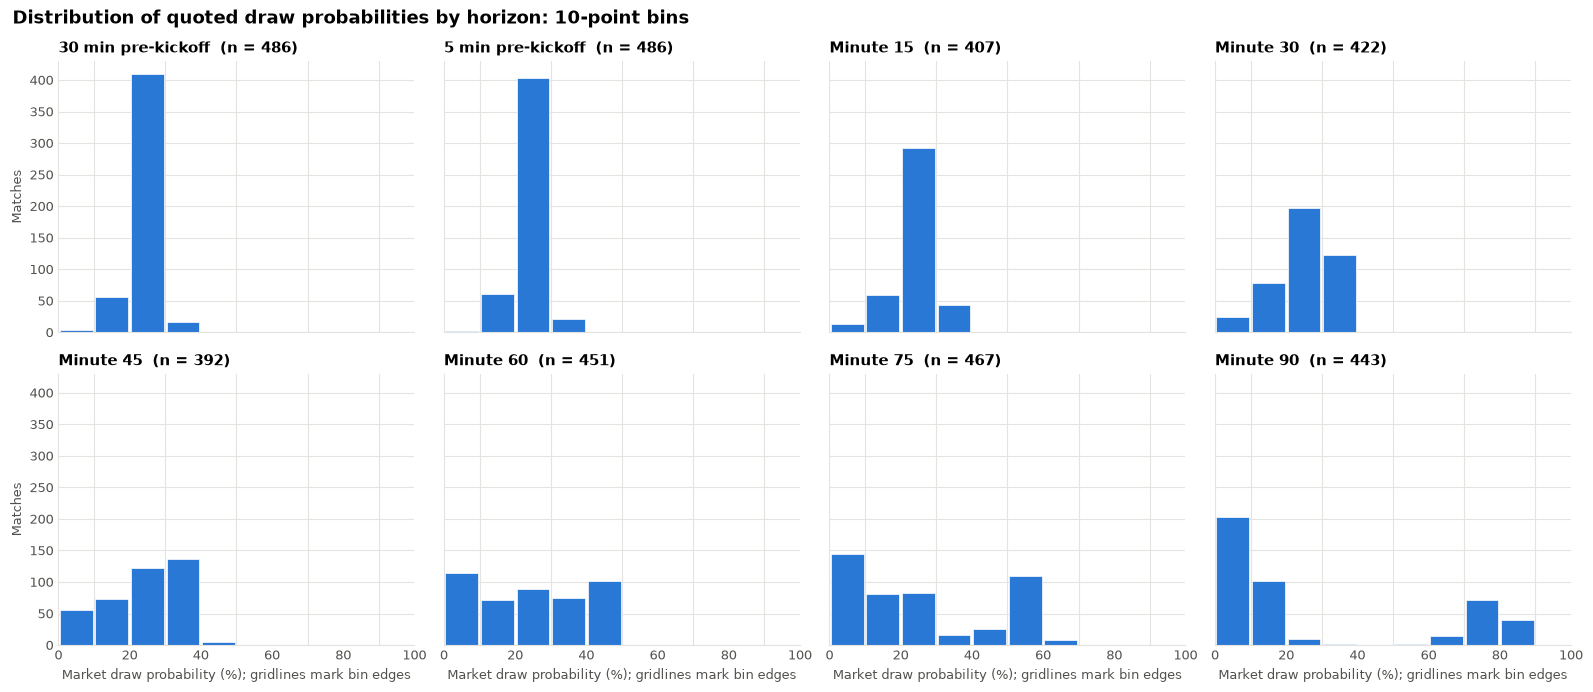

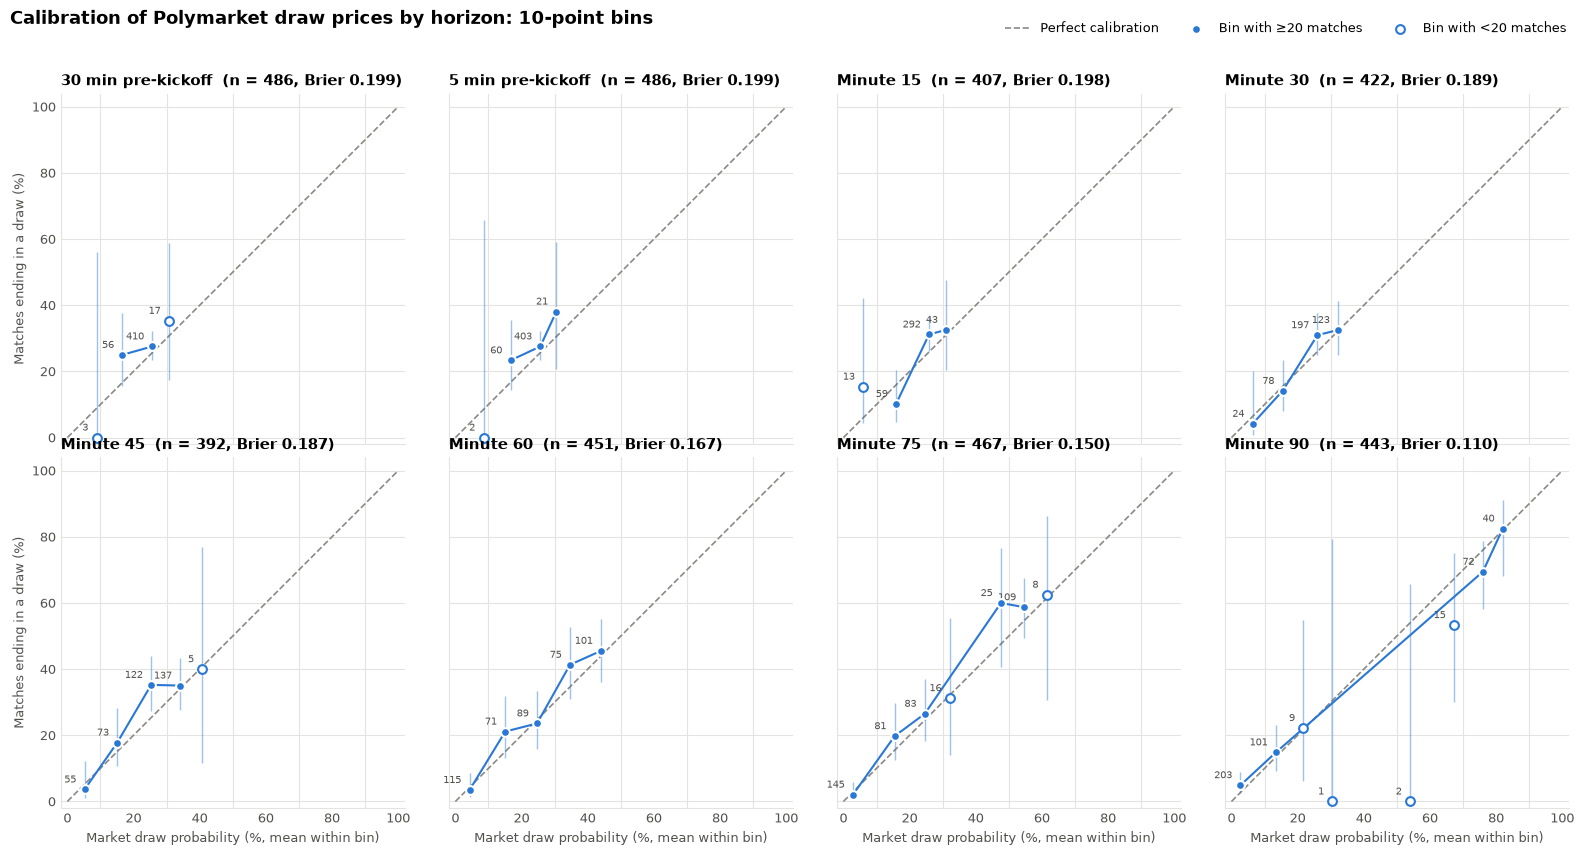

In [22]:
EDGES_10PT = np.round(np.linspace(0, 1, 11), 2)

results_10pt = run_calibration_analysis(eligible, EDGES_10PT, "10-point bins")

In [23]:
results_10pt["counts"]

prob_bin,0–10%,10–20%,20–30%,30–40%,40–50%,50–60%,60–70%,70–80%,80–90%,90–100%
forecast_horizon,,,,,,,,,,
pregame_30m,3,56,410,17,0,0,0,0,0,0
pregame_closing_5m,2,60,403,21,0,0,0,0,0,0
ingame_15m,13,59,292,43,0,0,0,0,0,0
ingame_30m,24,78,197,123,0,0,0,0,0,0
ingame_45m,55,73,122,137,5,0,0,0,0,0
ingame_60m,115,71,89,75,101,0,0,0,0,0
ingame_75m,145,81,83,16,25,109,8,0,0,0
ingame_90m,203,101,9,1,0,2,15,72,40,0


In [24]:
results_10pt["calibration"].round(3)

,forecast_horizon,prob_bin,matches,draws,mean_market_prob,actual_draw_rate,ci_low,ci_high,gap
0,pregame_30m,0–10%,3,0,0.088,0.000,0.000,0.562,-0.088
1,pregame_30m,10–20%,56,14,0.166,0.250,0.155,0.377,0.084
2,pregame_30m,20–30%,410,113,0.257,0.276,0.235,0.321,0.019
3,pregame_30m,30–40%,17,6,0.307,0.353,0.173,0.587,0.046
4,pregame_closing_5m,0–10%,2,0,0.085,0.000,0.000,0.658,-0.085
5,pregame_closing_5m,10–20%,60,14,0.167,0.233,0.144,0.354,0.067
6,pregame_closing_5m,20–30%,403,111,0.257,0.275,0.234,0.321,0.019
7,pregame_closing_5m,30–40%,21,8,0.305,0.381,0.208,0.591,0.076
8,ingame_15m,0–10%,13,2,0.060,0.154,0.043,0.422,0.094
9,ingame_15m,10–20%,59,6,0.159,0.102,0.047,0.205,-0.058


**Summary per horizon.** Brier score: mean squared error of the draw probability against the 0/1 outcome (lower is better). ECE (expected calibration error): the match-weighted average absolute gap between the market's mean probability and the actual draw rate across bins. Brier does not depend on the bins; ECE does.

In [25]:
results_10pt["summary"].round(3)

,matches,draw_rate,mean_market_prob,brier,ece
forecast_horizon,,,,,
pregame_30m,486,0.274,0.247,0.199,0.028
pregame_closing_5m,486,0.274,0.247,0.199,0.027
ingame_15m,407,0.278,0.243,0.198,0.051
ingame_30m,422,0.268,0.247,0.189,0.028
ingame_45m,392,0.276,0.239,0.187,0.041
ingame_60m,451,0.259,0.240,0.167,0.028
ingame_75m,467,0.278,0.254,0.150,0.030
ingame_90m,443,0.266,0.271,0.110,0.032


## Analysis 2: custom bins

Bins: 0–5%, 5–15%, 15–25%, 25–40%, 40–50%, 50–65%, 65–75%, 75–85%, 85–100%. These are narrower where prices cluster and wider where they're sparse.

Bins have unequal widths, so in the distribution charts each bar spans its true bin width and shows the number of matches in it; a wide bin can hold more matches simply because it covers more of the scale.

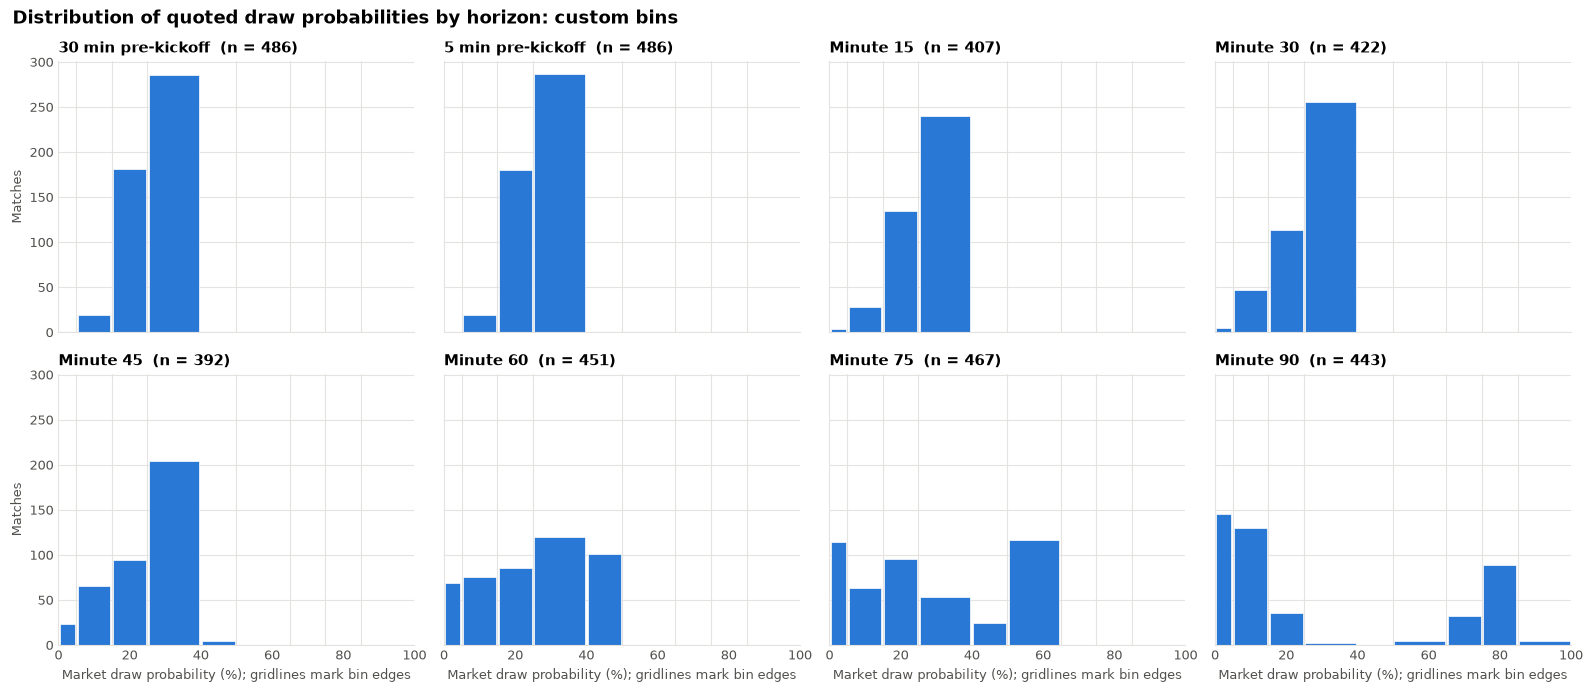

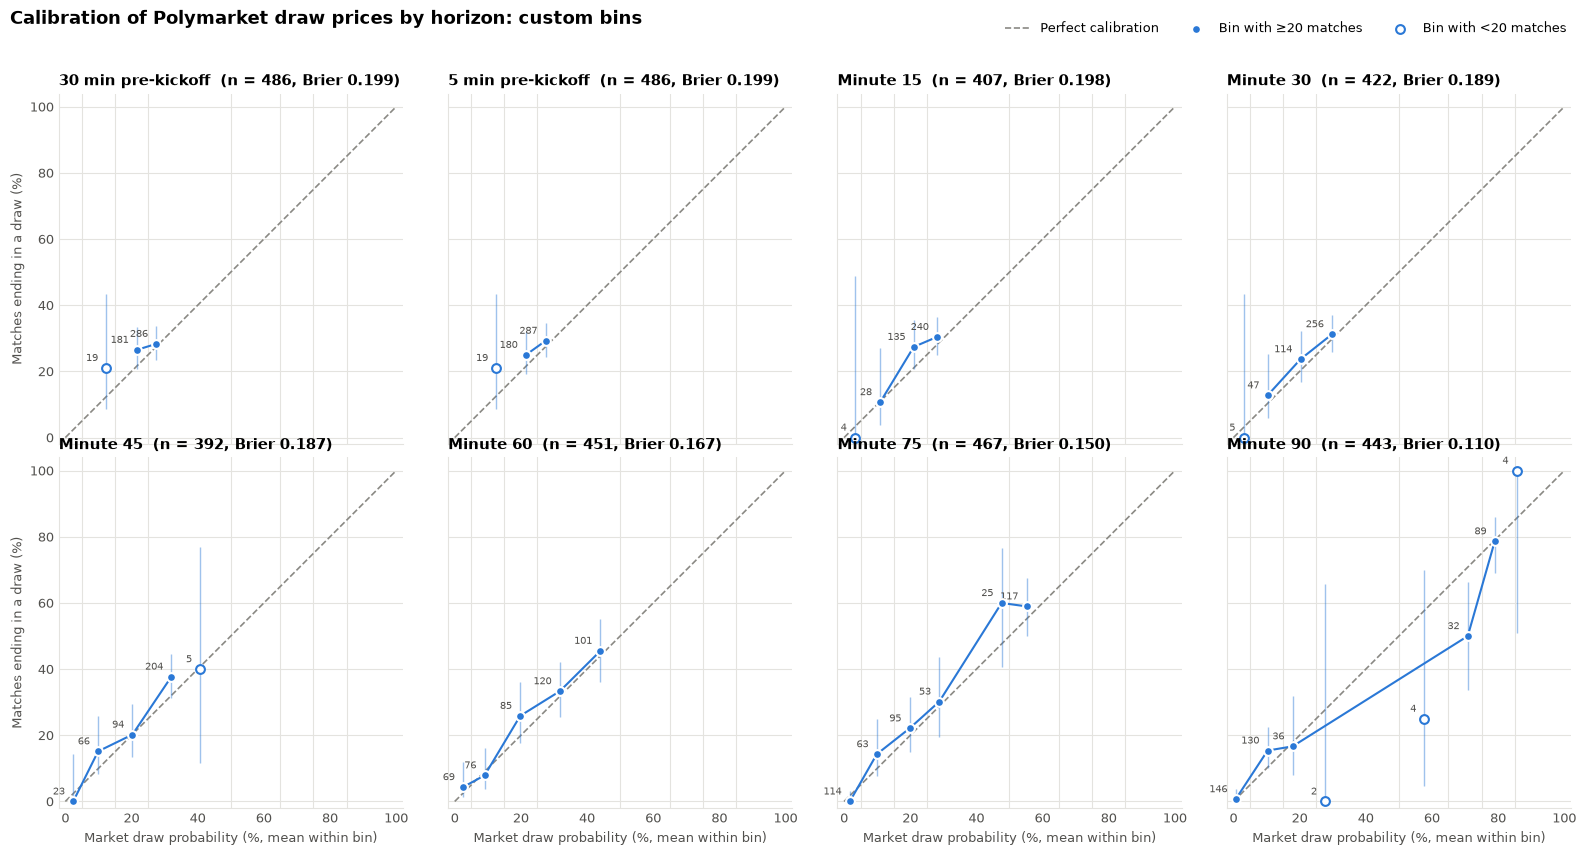

In [26]:
EDGES_CUSTOM = [0, 0.05, 0.15, 0.25, 0.40, 0.50, 0.65, 0.75, 0.85, 1.0]

results_custom = run_calibration_analysis(eligible, EDGES_CUSTOM, "custom bins")

In [27]:
results_custom["counts"]

prob_bin,0–5%,5–15%,15–25%,25–40%,40–50%,50–65%,65–75%,75–85%,85–100%
forecast_horizon,,,,,,,,,
pregame_30m,0,19,181,286,0,0,0,0,0
pregame_closing_5m,0,19,180,287,0,0,0,0,0
ingame_15m,4,28,135,240,0,0,0,0,0
ingame_30m,5,47,114,256,0,0,0,0,0
ingame_45m,23,66,94,204,5,0,0,0,0
ingame_60m,69,76,85,120,101,0,0,0,0
ingame_75m,114,63,95,53,25,117,0,0,0
ingame_90m,146,130,36,2,0,4,32,89,4


In [28]:
results_custom["calibration"].round(3)

,forecast_horizon,prob_bin,matches,draws,mean_market_prob,actual_draw_rate,ci_low,ci_high,gap
0,pregame_30m,5–15%,19,4,0.124,0.211,0.085,0.433,0.087
1,pregame_30m,15–25%,181,48,0.217,0.265,0.206,0.334,0.049
2,pregame_30m,25–40%,286,81,0.275,0.283,0.234,0.338,0.008
3,pregame_closing_5m,5–15%,19,4,0.126,0.211,0.085,0.433,0.085
4,pregame_closing_5m,15–25%,180,45,0.215,0.250,0.192,0.318,0.035
5,pregame_closing_5m,25–40%,287,84,0.275,0.293,0.243,0.348,0.018
6,ingame_15m,0–5%,4,0,0.033,0.000,0.000,0.490,-0.033
7,ingame_15m,5–15%,28,3,0.109,0.107,0.037,0.272,-0.002
8,ingame_15m,15–25%,135,37,0.211,0.274,0.206,0.355,0.064
9,ingame_15m,25–40%,240,73,0.281,0.304,0.249,0.365,0.023


In [29]:
results_custom["summary"].round(3)

,matches,draw_rate,mean_market_prob,brier,ece
forecast_horizon,,,,,
pregame_30m,486,0.274,0.247,0.199,0.026
pregame_closing_5m,486,0.274,0.247,0.199,0.027
ingame_15m,407,0.278,0.243,0.198,0.035
ingame_30m,422,0.268,0.247,0.189,0.021
ingame_45m,392,0.276,0.239,0.187,0.040
ingame_60m,451,0.259,0.240,0.167,0.024
ingame_75m,467,0.278,0.254,0.150,0.033
ingame_90m,443,0.266,0.271,0.110,0.037


### Comparing the two binnings

Brier score is identical across binnings (it uses each match's own price). ECE changes because it depends on how matches are grouped.

In [30]:
pd.DataFrame({
    "brier": results_10pt["summary"]["brier"],
    "ece_10pt": results_10pt["summary"]["ece"],
    "ece_custom": results_custom["summary"]["ece"],
}).round(3)

,brier,ece_10pt,ece_custom
forecast_horizon,,,
pregame_30m,0.199,0.028,0.026
pregame_closing_5m,0.199,0.027,0.027
ingame_15m,0.198,0.051,0.035
ingame_30m,0.189,0.028,0.021
ingame_45m,0.187,0.041,0.040
ingame_60m,0.167,0.028,0.024
ingame_75m,0.150,0.030,0.033
ingame_90m,0.110,0.032,0.037
